# Lab 1.5 · Causal attention

**15–20 minutes · CPU · Python standard library**

## How to work through this notebook

Read the worked example, run the setup, then complete the exercises in order. Replace each `return None` placeholder with your code and run the cell below to check your result. Use the wrap-up to explain the output in your own words.

## Concepts and worked example

Attention uses a **query** to ask what information is relevant, a **key** to score how well each source position matches, and a **value** to supply the information to mix. For one query, take its dot product with each key and divide by the square root of the key width. Softmax turns the resulting scores into nonnegative weights that sum to one.

For query `[1, 0]` and keys `[1, 0]` and `[0, 1]`, the scaled scores are about `[0.707, 0]`. If both keys are visible, the weights are about `[0.67, 0.33]`. With values `[3, 0]` and `[0, 6]`, the weighted output is about `[2.01, 1.98]`.

**Causal** attention means position i can read positions up to and including i. For the first query in the example, masking the second score before softmax gives weights `[1, 0]` and output `[3, 0]`. The notebook holds queries, keys, and values fixed so you can isolate what scoring and masking do.

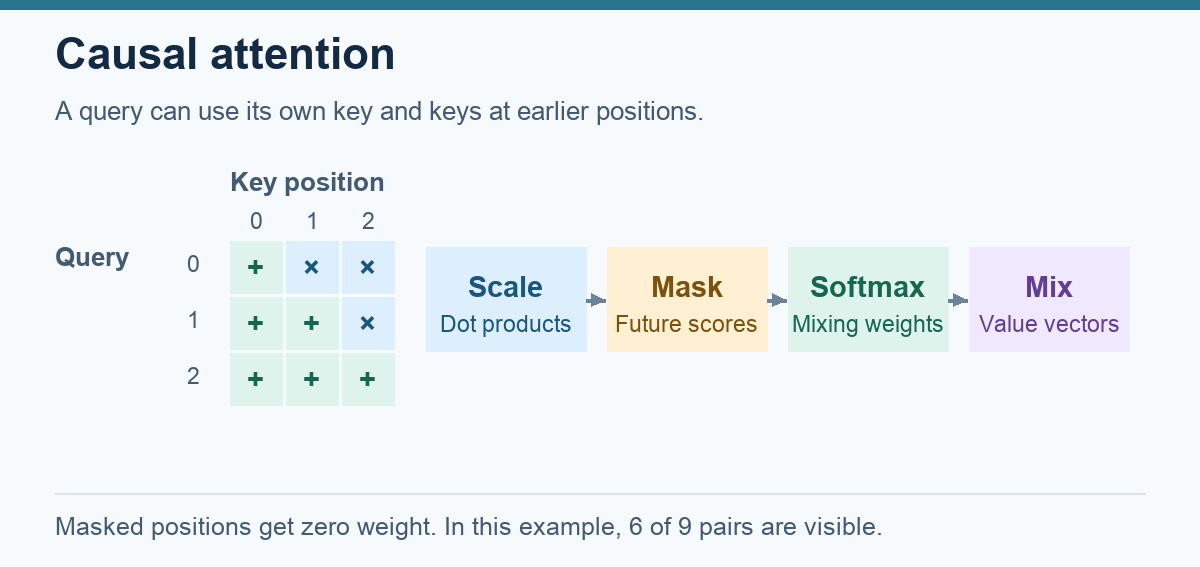

## Exercise map

1. **Score and mask keys** — Compute one scaled dot product per key. Use negative infinity for future keys when the causal mask is enabled.
2. **Mix values and test causality** — Use the weights to build the output vector, then change only the final value and compare masked and unmasked runs.

[Open the lab guide](README.md) for the exercise checklist.

In [ ]:
from math import exp, isclose, sqrt

queries = [[1, 0], [1, 0], [0, 1]]
keys = [[1, 0], [0, 1], [2, 1]]
values = [[1, 0], [0, 2], [3, 3]]

def attention_weights(scores):
    shifted = [exp(score - max(scores)) for score in scores]
    total = sum(shifted)
    return [weight / total for weight in shifted]

## Exercise 1. Score and mask keys

For query index i and key index j, compute their dot product divided by the square root of the key width. If causal masking is on and j is greater than i, use negative infinity.

**Implementation hint** — Compare the key index j with the query index i before returning a score. The scale depends on the key vector width.

**After running the check** — Inspect the first softmax row. The first position can only attend to itself, so all weight goes to that key.

In [ ]:
def score_row(i, queries, keys, causal):
    return None

In [ ]:
scores = score_row(0, queries, keys, True)
if scores is not None:
    assert isclose(scores[0], 1 / sqrt(2))
    assert scores[1:] == [float("-inf")] * 2
    assert all(score != float("-inf") for score in score_row(0, queries, keys, False))
    print("PASS — first weight row:", attention_weights(scores))

## Exercise 2. Mix values and test causality

Compute a weighted sum for each value feature. Then compare the output with the causal mask on and off. Predict which rows change when only the final value vector changes.

**Implementation hint** — For a given output feature, sum weight[j] times the same feature of value row j across source positions.

**After running the check** — With masking, the final value can affect the last output, while earlier outputs stay fixed. The unmasked run provides a comparison.

In [ ]:
def mix_values(weights, values):
    return None

In [ ]:
if scores is not None and mix_values([1, 0, 0], values) is not None:
    def attention(values, causal):
        weights = [attention_weights(score_row(i, queries, keys, causal))
                   for i in range(len(queries))]
        assert all(isclose(sum(row), 1.0) for row in weights)
        return weights, [mix_values(row, values) for row in weights]

    masked_weights, masked = attention(values, True)
    _, unmasked = attention(values, False)
    changed = [*values[:-1], [30, 30]]
    _, masked_changed = attention(changed, True)
    _, unmasked_changed = attention(changed, False)
    assert masked[0] == values[0]
    assert masked_changed[:2] == masked[:2] and masked_changed[2] != masked[2]
    assert unmasked_changed[0] != unmasked[0]
    pairs = [(i, j) for i, row in enumerate(masked_weights) for j, w in enumerate(row) if w > 0]
    print("Visible query-key pairs:", len(pairs), "of", len(queries) * len(keys))
    for row in masked_weights:
        print([round(w, 3) for w in row])
    print("PASS — early causal outputs ignore future values")

## Wrap-up

In a new cell, append a fourth query and key. Use `score_row` and `attention_weights` to count the visible pairs again. Predict the new count before running that cell. Does a causal mask alone save dot products in every attention implementation?